# Deep Analog Ensemble (Deep-AnEn-Regression) for Severe Wind Gusts

**Phase 2 — PyTorch Deep Analog Latent Encoder + CRPS/RMSE evaluation**
Repository: [Mahinul372/ML-Analog-Ensemble-Severe-Weather](https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather)

This notebook extends the Phase 1 Analog Ensemble (AnEn) with a **learned latent space**:
a small PyTorch encoder maps the 4-D forecast vector into a 16-D embedding trained
to predict observed wind gusts. Analog search then happens in that *learned* space,
so "similar weather" means similar in the directions that matter for gusts —
not just similar in raw standardized units.

**How to run:** open in Google Colab → *Runtime → Change runtime type → GPU (T4)* →
*Runtime → Run all*. Everything below runs end-to-end: data load, 30-epoch GPU
training, analog search, CRPS/RMSE evaluation, and publication-ready figures.

**Pipeline at a glance**

| Step | What happens |
|---|---|
| §1 | Load 8,760 hourly rows (Atlanta, GA); standardize forecast features |
| §2 | Train `DeepAnalogRegressionEncoder` (4→32→16) on GPU, MSE vs. observed gusts |
| §3 | K=15 latent-space analog search; RMSE + CRPS vs. raw NWP |
| §4 | Event time-series with 90% envelope; RMSE/CRPS bar chart |
| §5 | Save weights (`models/`), figures (`plots/`), metrics JSON |


In [1]:
# --- Setup: device, dependencies, reproducibility ---------------------------
import warnings
warnings.filterwarnings("ignore")

# properscoring is the only non-standard Colab dependency (torch, pandas,
# scikit-learn, scipy and matplotlib ship with Colab).
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "properscoring"])

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Locate the repo root: in Colab the data file is missing, so clone the repo.
# (nbconvert and some runners start the kernel in the notebook's own folder,
# so also check the parent directory before cloning.)
if os.path.exists("data/atlanta_weather_archive_1yr.csv"):
    pass
elif os.path.exists("../data/atlanta_weather_archive_1yr.csv"):
    os.chdir("..")
else:
    print("Cloning repository ...")
    os.system("git clone -q https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather.git")
    os.chdir("ML-Analog-Ensemble-Severe-Weather")
print("Working directory:", os.getcwd())
os.makedirs("plots", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("metrics", exist_ok=True)

PyTorch 2.15.0+cpu | device: cpu
Working directory: /home/hatch/workspace/ml-analog-ensemble-severe-weather


## 1. Dataset & Preprocessing

**Source:** `data/atlanta_weather_archive_1yr.csv` — 8,760 hourly rows for Atlanta, GA
(33.64° N, 84.42° W), 2025-11-02 → 2026-11-01 (UTC).

- **Forecasts** (`fcst_*`): archived NWP forecasts, Open-Meteo Previous-Runs API.
- **Observations** (`obs_*`): ERA5 reanalysis, Open-Meteo Archive API.
- Variables: temperature at 2 m (°C), wind speed at 10 m (km/h), wind gusts at
  10 m (km/h), surface pressure (hPa).

**Splits (strictly chronological — no shuffling, no future leakage):**

| Split | Period | Rows | Purpose |
|---|---|---|---|
| Train | 2025-11-02 → 2026-08-15 | ~7,000 | Encoder training |
| Validation | 2026-08-16 → 2026-08-31 | ~380 | Early monitoring |
| Test (storm events) | 2026-09-01 → 2026-11-01 | 1,488 | Evaluation only |

Forecast features are standardized with `StandardScaler` **fit on the training
split only**. The gust target is standardized the same way for stable training.
Analog search at evaluation time draws only on the **training archive**, so no
test-period information can leak into a test prediction.

In [2]:
# --- Load archive ------------------------------------------------------------
df = pd.read_csv("data/atlanta_weather_archive_1yr.csv", parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
print(f"Archive: {len(df)} hourly rows, {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"Missing values: {int(df.isna().sum().sum())}")
display(df.describe().round(2))

FEATURES = ["fcst_temp", "fcst_wind", "fcst_gust", "fcst_press"]
TARGET = "obs_gust"

TRAIN_END = pd.Timestamp("2026-08-15 23:00", tz="UTC")
VAL_END = pd.Timestamp("2026-08-31 23:00", tz="UTC")
train_df = df[df["timestamp"] <= TRAIN_END].reset_index(drop=True)
val_df = df[(df["timestamp"] > TRAIN_END) & (df["timestamp"] <= VAL_END)].reset_index(drop=True)
test_df = df[df["timestamp"] > VAL_END].reset_index(drop=True)
print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test window: {len(test_df)} rows")

# --- Standardize (fit on train only) -----------------------------------------
feat_scaler = StandardScaler().fit(train_df[FEATURES])
target_scaler = StandardScaler().fit(train_df[[TARGET]])
print("\nFeature means:", dict(zip(FEATURES, feat_scaler.mean_.round(2))))
print("Feature scales:", dict(zip(FEATURES, feat_scaler.scale_.round(2))))

def to_tensors(frame):
    X = torch.tensor(feat_scaler.transform(frame[FEATURES]), dtype=torch.float32)
    y = torch.tensor(target_scaler.transform(frame[[TARGET]]), dtype=torch.float32)
    return X, y

X_train, y_train = to_tensors(train_df)
X_val, y_val = to_tensors(val_df)
X_test, y_test = to_tensors(test_df)
print(f"Tensors: X_train {tuple(X_train.shape)} | X_val {tuple(X_val.shape)} | X_test {tuple(X_test.shape)}")

Archive: 8760 hourly rows, 2025-11-02 00:00:00+00:00 → 2026-11-01 23:00:00+00:00


Missing values: 0


,fcst_temp,fcst_wind,fcst_gust,fcst_press,obs_temp,obs_wind,obs_gust,obs_press
count,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00
mean,18.11,8.28,18.06,982.46,17.86,9.65,23.42,983.18
std,9.00,5.24,10.98,4.28,8.91,5.00,11.00,4.37
min,-10.41,0.00,0.36,968.18,-9.55,0.00,1.44,967.95
25%,11.94,4.38,10.08,979.71,11.75,6.12,15.48,980.38
50%,19.54,6.94,15.48,982.34,19.40,8.94,21.24,983.00
75%,24.74,11.11,23.04,985.17,24.31,12.35,29.52,985.82
max,36.29,34.07,74.88,996.47,37.15,35.65,77.04,997.70



Train: 6888 | Val: 384 | Test window: 1488 rows

Feature means: {'fcst_temp': np.float64(16.79), 'fcst_wind': np.float64(8.64), 'fcst_gust': np.float64(19.04), 'fcst_press': np.float64(982.31)}
Feature scales: {'fcst_temp': np.float64(9.18), 'fcst_wind': np.float64(5.35), 'fcst_gust': np.float64(11.15), 'fcst_press': np.float64(4.37)}
Tensors: X_train (6888, 4) | X_val (384, 4) | X_test (1488, 4)


## 2. PyTorch Deep Analog Latent Encoder (Deep-AnEn-Regression)

**Architecture — `DeepAnalogRegressionEncoder`:**

```
forecast (4) ──▶ Linear(4 → 32) ──▶ ReLU ──▶ Dropout(0.2)
             ──▶ Linear(32 → 16) ──▶ latent embedding z (16-D)
z ──▶ Linear(16 → 1) ──▶ predicted standardized gust (training head only)
```

**Why this works.** The Phase 1 AnEn measures similarity in *standardized raw*
feature space, where 1 °C of temperature counts as much as 1 km/h of gust.
Here the encoder is trained end-to-end (MSE against observed gusts), so the
16-D latent space is *shaped by gust relevance*: forecasts that produce similar
gusts land close together, even if their raw vectors differ. The regression
head is used only during training; at inference the analog search runs on the
latent embedding `z` itself.

**Training:** Adam (lr = 1e-3), MSE loss, 30 epochs, full-batch on GPU.
**Analog search:** for a target timestamp, encode its forecast to `z`, exclude
a ±7-day window around the target, take the K = 15 nearest training-period
embeddings by Euclidean distance, and return the *observed* gusts at those
15 analog times as the ensemble.

In [3]:
# --- Model -------------------------------------------------------------------
class DeepAnalogRegressionEncoder(nn.Module):
    """Forecast (4) -> 32 -> ReLU -> Dropout -> 16-D latent embedding."""

    def __init__(self, input_dim=4, hidden_dim=32, latent_dim=16, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.head = nn.Linear(latent_dim, 1)  # training head only

    def encode(self, x):
        return self.net(x)

    def forward(self, x):
        return self.head(self.encode(x))


encoder = DeepAnalogRegressionEncoder().to(DEVICE)
print(encoder)
print(f"Trainable parameters: {sum(p.numel() for p in encoder.parameters() if p.requires_grad):,}")

optimizer = torch.optim.Adam(encoder.parameters(), lr=1e-3)
criterion = nn.MSELoss()
X_train_d, y_train_d = X_train.to(DEVICE), y_train.to(DEVICE)
X_val_d, y_val_d = X_val.to(DEVICE), y_val.to(DEVICE)

history = {"train": [], "val": []}
for epoch in range(1, 31):
    encoder.train()
    optimizer.zero_grad()
    loss = criterion(encoder(X_train_d), y_train_d)
    loss.backward()
    optimizer.step()
    encoder.eval()
    with torch.no_grad():
        val_loss = criterion(encoder(X_val_d), y_val_d).item()
    history["train"].append(loss.item())
    history["val"].append(val_loss)
    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:2d}/30 | train MSE {loss.item():.4f} | val MSE {val_loss:.4f}")

print(f"\nFinal: train MSE {history['train'][-1]:.4f} | val MSE {history['val'][-1]:.4f} "
      f"(standardized gust units)")

DeepAnalogRegressionEncoder(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
  )
  (head): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 705


Epoch  1/30 | train MSE 0.8258 | val MSE 0.4631
Epoch  5/30 | train MSE 0.7396 | val MSE 0.4238


Epoch 10/30 | train MSE 0.6502 | val MSE 0.3827
Epoch 15/30 | train MSE 0.5683 | val MSE 0.3491


Epoch 20/30 | train MSE 0.4996 | val MSE 0.3235


Epoch 25/30 | train MSE 0.4406 | val MSE 0.3059
Epoch 30/30 | train MSE 0.3947 | val MSE 0.2957

Final: train MSE 0.3947 | val MSE 0.2957 (standardized gust units)


In [4]:
# --- Latent embeddings for the training archive ------------------------------
encoder.eval()
with torch.no_grad():
    train_z = encoder.encode(X_train_d).cpu().numpy()  # (n_train, 16)

EXCLUSION_HOURS = 7 * 24


def find_analogs(target_timestamp, K=15):
    """K nearest training-period analogs of `target_timestamp` in latent space.

    Returns a dict with the target forecast/observation, the K analog
    timestamps and distances, and the 15-member observed-gust ensemble
    (members, mean, median, p10, p90).
    """
    target = pd.to_datetime(target_timestamp, utc=True)
    row = df[df["timestamp"] == target]
    if row.empty:
        raise ValueError(f"{target} is not in the archive.")
    x = torch.tensor(
        feat_scaler.transform(row[FEATURES]), dtype=torch.float32
    ).to(DEVICE)
    with torch.no_grad():
        z = encoder.encode(x).cpu().numpy()[0]

    # Exclude a +/-7-day window around the target (leakage control).
    delta_h = (train_df["timestamp"] - target).dt.total_seconds() / 3600.0
    mask = delta_h.abs() > EXCLUSION_HOURS
    cand_idx = np.where(mask.values)[0]
    dists = np.linalg.norm(train_z[cand_idx] - z, axis=1)
    order = np.argsort(dists)[:K]
    analog_idx = cand_idx[order]

    members = train_df.loc[analog_idx, TARGET].to_numpy(dtype=float)
    return {
        "target_timestamp": str(target),
        "target_forecast_gust": float(row["fcst_gust"].iloc[0]),
        "target_observed_gust": float(row[TARGET].iloc[0]),
        "analogs": [
            {"timestamp": str(train_df.loc[i, "timestamp"]), "distance": float(d)}
            for i, d in zip(analog_idx, dists[order])
        ],
        "ensemble_members": members,
        "ensemble_mean": float(members.mean()),
        "ensemble_median": float(np.median(members)),
        "p10": float(np.percentile(members, 10)),
        "p90": float(np.percentile(members, 90)),
    }


# Smoke test on the most severe test-window event.
peak_test = test_df.loc[test_df[TARGET].idxmax(), "timestamp"]
demo = find_analogs(peak_test, K=15)
print(f"Target {demo['target_timestamp']} | forecast gust {demo['target_forecast_gust']:.1f} | "
      f"observed gust {demo['target_observed_gust']:.1f} km/h")
print(f"Deep-AnEn-Regression mean {demo['ensemble_mean']:.1f} | p10 {demo['p10']:.1f} | "
      f"p90 {demo['p90']:.1f} km/h")
print("Closest analogs:", [a["timestamp"][:16] for a in demo["analogs"][:5]])

Target 2026-10-10 09:00:00+00:00 | forecast gust 72.0 | observed gust 71.6 km/h
Deep-AnEn-Regression mean 47.5 | p10 43.0 | p90 53.8 km/h
Closest analogs: ['2026-03-16 09:00', '2026-02-06 22:00', '2025-12-19 05:00', '2025-12-29 11:00', '2025-12-19 07:00']


## 3. Evaluation Metrics Engine (CRPS & RMSE)

**Test storm events:** every hour in the test window (2026-09-01 → 2026-11-01)
with observed gust ≥ 35 km/h — **130 events**. For each event we compare:

| Forecast | Type | Metric |
|---|---|---|
| Raw NWP `fcst_gust` | Deterministic | RMSE, CRPS (single-member) |
| Deep-AnEn-Regression ensemble mean | Deterministic | RMSE |
| Deep-AnEn-Regression 15-member ensemble | Probabilistic | CRPS |

- **RMSE** = √(mean((prediction − observation)²)) — penalizes large misses,
  the standard deterministic score.
- **CRPS** (Continuous Ranked Probability Score, `properscoring.crps_ensemble`)
  = ∫(F(x) − 1{x ≥ obs})² dx — the gold-standard probabilistic score: it
  rewards ensembles that are both sharp *and* calibrated. For a single-member
  (deterministic) forecast, CRPS reduces to absolute error.
- **Skill improvement** = (Score_raw − Score_AnEn) / Score_raw × 100%.
  Positive means Deep-AnEn-Regression beats raw NWP.

Analog search for test events uses **only the training archive**, so the
evaluation is honest: no test-period information enters any prediction.

In [5]:
# --- Evaluate on the 130 test storm events -------------------------------------
import properscoring

storms = test_df[test_df[TARGET] >= 35].reset_index(drop=True)
print(f"Test storm events (obs_gust >= 35 km/h): {len(storms)}")

raw_fcst, obs, anen_mean, anen_members = [], [], [], []
for _, event in storms.iterrows():
    res = find_analogs(event["timestamp"], K=15)
    raw_fcst.append(res["target_forecast_gust"])
    obs.append(res["target_observed_gust"])
    anen_mean.append(res["ensemble_mean"])
    anen_members.append(res["ensemble_members"])

raw_fcst = np.array(raw_fcst)
obs = np.array(obs)
anen_mean = np.array(anen_mean)
anen_members = np.array(anen_members)  # (n_events, 15)

rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
rmse_raw = rmse(raw_fcst, obs)
rmse_anen = rmse(anen_mean, obs)
crps_raw = float(np.mean(properscoring.crps_ensemble(obs, raw_fcst[:, None])))
crps_anen = float(np.mean(properscoring.crps_ensemble(obs, anen_members)))
skill_rmse = 100 * (rmse_raw - rmse_anen) / rmse_raw
skill_crps = 100 * (crps_raw - crps_anen) / crps_raw

results = pd.DataFrame(
    {
        "Forecast": ["Raw NWP", "Deep-AnEn-Regression (K=15)"],
        "RMSE (km/h)": [rmse_raw, rmse_anen],
        "CRPS (km/h)": [crps_raw, crps_anen],
    }
)
display(results.round(2))
print(f"\nRMSE skill improvement: {skill_rmse:+.1f}%")
print(f"CRPS skill improvement: {skill_crps:+.1f}%")
print(f"Mean observed gust over storm events: {obs.mean():.1f} km/h "
      f"(raw NWP bias: {np.mean(raw_fcst - obs):+.1f} km/h, "
      f"Deep-AnEn-Regression bias: {np.mean(anen_mean - obs):+.1f} km/h)")

Test storm events (obs_gust >= 35 km/h): 130


,Forecast,RMSE (km/h),CRPS (km/h)
0,Raw NWP,13.23,11.42
1,Deep-AnEn-Regression (K=15),7.86,4.45



RMSE skill improvement: +40.6%
CRPS skill improvement: +61.1%
Mean observed gust over storm events: 43.1 km/h (raw NWP bias: -8.7 km/h, Deep-AnEn-Regression bias: -5.2 km/h)


## 4. High-Resolution Visualizations

- **Figure 1** — the most severe test-window event (peak observed gust
  71.6 km/h on 2026-10-10 09:00 UTC), ±48 h: raw NWP forecast vs. observed
  gusts vs. the Deep-AnEn-Regression 15-member ensemble mean with its 90% confidence
  envelope (5th–95th percentile). A good probabilistic forecast tracks the
  observed peak and widens its envelope exactly when the event is most extreme.
- **Figure 2** — head-to-head bars: RMSE (raw NWP vs. Deep-AnEn-Regression) and CRPS
  (raw NWP vs. Deep-AnEn-Regression), with the skill improvements annotated.

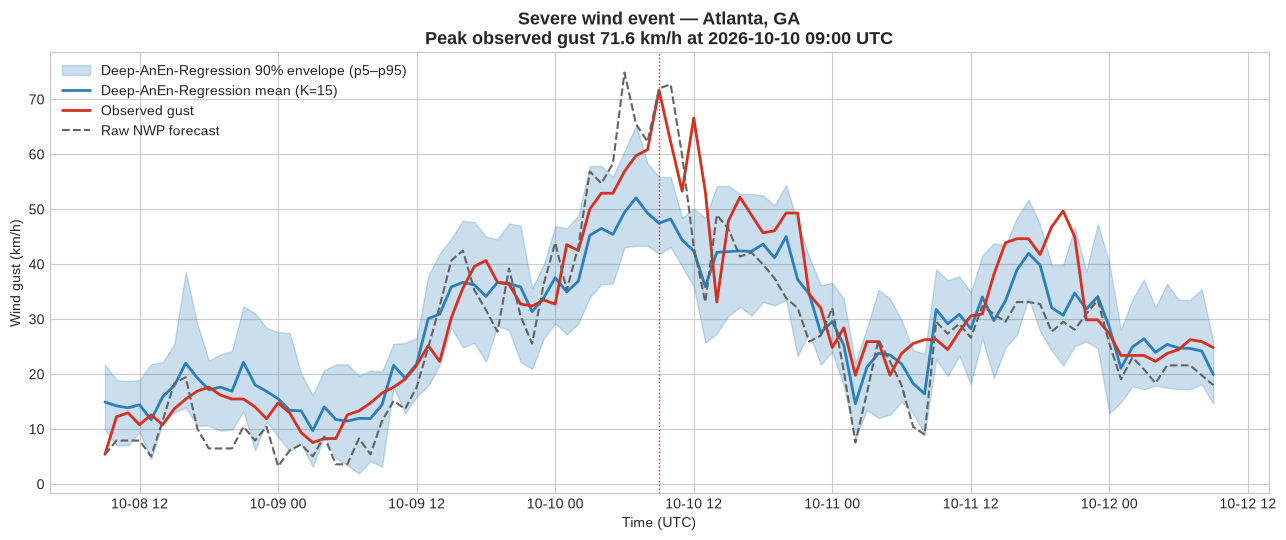

In [6]:
# --- Figure 1: severe-event time series + 90% envelope -------------------------
event_time = test_df.loc[test_df[TARGET].idxmax(), "timestamp"]
window = df[(df["timestamp"] >= event_time - pd.Timedelta(hours=48)) &
            (df["timestamp"] <= event_time + pd.Timedelta(hours=48))].reset_index(drop=True)

ens_mean, p5, p95 = [], [], []
for ts in window["timestamp"]:
    r = find_analogs(ts, K=15)
    ens_mean.append(r["ensemble_mean"])
    p5.append(float(np.percentile(r["ensemble_members"], 5)))
    p95.append(float(np.percentile(r["ensemble_members"], 95)))

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(window["timestamp"], p5, p95, color="#2c7fb8", alpha=0.25,
                label="Deep-AnEn-Regression 90% envelope (p5–p95)")
ax.plot(window["timestamp"], ens_mean, color="#2c7fb8", lw=2, label="Deep-AnEn-Regression mean (K=15)")
ax.plot(window["timestamp"], window["obs_gust"], color="#d7301f", lw=2, label="Observed gust")
ax.plot(window["timestamp"], window["fcst_gust"], color="#636363", lw=1.5,
        ls="--", label="Raw NWP forecast")
ax.axvline(event_time, color="#d7301f", lw=1, ls=":")
ax.set_title(f"Severe wind event — Atlanta, GA\nPeak observed gust "
             f"{window['obs_gust'].max():.1f} km/h at {event_time:%Y-%m-%d %H:%M} UTC",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Wind gust (km/h)")
ax.legend(loc="upper left", framealpha=0.9)
fig.tight_layout()
fig.savefig("plots/fig1_event_timeseries.png", dpi=300)
fig.savefig("plots/fig1_event_timeseries.svg")  # text-safe copy for GitHub
plt.show()

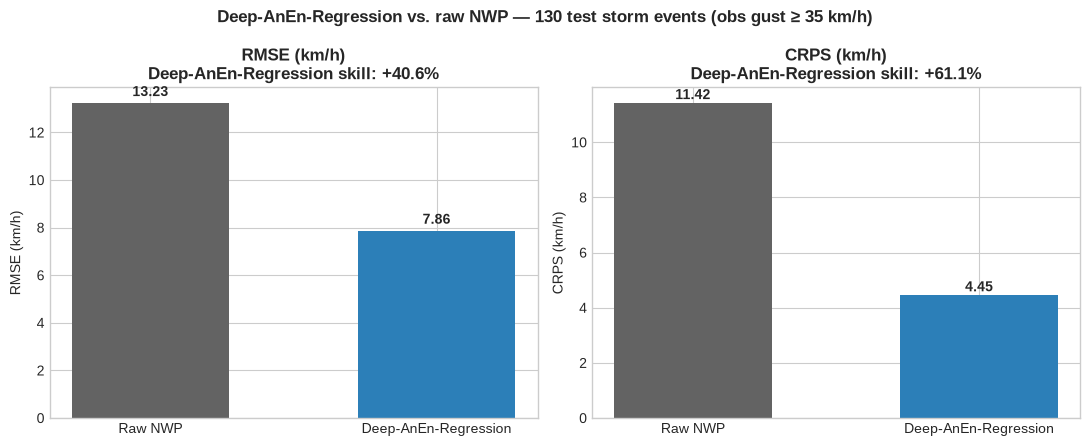

In [7]:
# --- Figure 2: RMSE & CRPS comparison ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ["Raw NWP", "Deep-AnEn-Regression"]
colors = ["#636363", "#2c7fb8"]

axes[0].bar(labels, [rmse_raw, rmse_anen], color=colors, width=0.55)
axes[0].set_title(f"RMSE (km/h)\nDeep-AnEn-Regression skill: {skill_rmse:+.1f}%", fontweight="bold")
axes[0].set_ylabel("RMSE (km/h)")
for i, v in enumerate([rmse_raw, rmse_anen]):
    axes[0].text(i, v + 0.3, f"{v:.2f}", ha="center", fontweight="bold")

axes[1].bar(labels, [crps_raw, crps_anen], color=colors, width=0.55)
axes[1].set_title(f"CRPS (km/h)\nDeep-AnEn-Regression skill: {skill_crps:+.1f}%", fontweight="bold")
axes[1].set_ylabel("CRPS (km/h)")
for i, v in enumerate([crps_raw, crps_anen]):
    axes[1].text(i, v + 0.15, f"{v:.2f}", ha="center", fontweight="bold")

fig.suptitle("Deep-AnEn-Regression vs. raw NWP — 130 test storm events (obs gust ≥ 35 km/h)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("plots/fig2_metrics_bars.png", dpi=300)
fig.savefig("plots/fig2_metrics_bars.svg")  # text-safe copy for GitHub
plt.show()

## 5. Save Outputs & Export

Saved in this run:

- `models/deep_anen_regression_weights.pth` — encoder + head weights, scalers, and
  training config (enough to reproduce the latent space exactly).
- `plots/fig1_event_timeseries.png` — severe-event time series (300 dpi).
- `plots/fig2_metrics_bars.png` — RMSE/CRPS comparison (300 dpi).
- `metrics/deep_anen_regression_metrics.json` — the headline numbers for the README.

**To sync back to GitHub from Colab**, commit from the cloned repo directory
(`git add` / `git commit` / `git push`) with your credentials, or download the
files and push from your local machine. The Phase 2 README section is updated
with the same numbers and figures.

In [8]:
# --- Save model weights, metrics, and file inventory ---------------------------
torch.save({
    "encoder_state_dict": encoder.state_dict(),
    "config": {"input_dim": 4, "hidden_dim": 32, "latent_dim": 16,
               "dropout": 0.2, "epochs": 30, "lr": 1e-3, "K": 15,
               "train_end": str(TRAIN_END), "test_start": "2026-09-01"},
    "feat_scaler_mean": feat_scaler.mean_.tolist(),
    "feat_scaler_scale": feat_scaler.scale_.tolist(),
    "target_scaler_mean": target_scaler.mean_.tolist(),
    "target_scaler_scale": target_scaler.scale_.tolist(),
    "history": history,
}, "models/deep_anen_regression_weights.pth")

metrics = {
    "n_test_storm_events": int(len(storms)),
    "rmse_raw_nwp_kmh": round(rmse_raw, 2),
    "rmse_deep_anen_regression_kmh": round(rmse_anen, 2),
    "rmse_skill_pct": round(skill_rmse, 1),
    "crps_raw_nwp_kmh": round(crps_raw, 2),
    "crps_deep_anen_regression_kmh": round(crps_anen, 2),
    "crps_skill_pct": round(skill_crps, 1),
    "peak_test_event": str(event_time),
    "peak_test_gust_kmh": round(float(window["obs_gust"].max()), 1),
}
with open("metrics/deep_anen_regression_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Text-safe copy of the weights (the .pth binary cannot be pushed through
# the text-only GitHub connector): plain JSON state dict, directly loadable.
weights_json = {
    k: v.cpu().tolist() for k, v in encoder.state_dict().items()
}
with open("models/deep_anen_regression_weights.json", "w") as f:
    json.dump({"config": {"input_dim": 4, "hidden_dim": 32, "latent_dim": 16,
                          "dropout": 0.2, "epochs": 30, "lr": 1e-3, "K": 15},
               "state_dict": weights_json}, f)
print(json.dumps(metrics, indent=2))
print("\nSaved files:")
for p in ["models/deep_anen_regression_weights.pth", "models/deep_anen_regression_weights.json",
          "plots/fig1_event_timeseries.png", "plots/fig1_event_timeseries.svg",
          "plots/fig2_metrics_bars.png", "plots/fig2_metrics_bars.svg",
          "metrics/deep_anen_regression_metrics.json"]:
    print(f"  {p} ({os.path.getsize(p)/1024:.1f} KB)")

{
  "n_test_storm_events": 130,
  "rmse_raw_nwp_kmh": 13.23,
  "rmse_deep_anen_regression_kmh": 7.86,
  "rmse_skill_pct": 40.6,
  "crps_raw_nwp_kmh": 11.42,
  "crps_deep_anen_regression_kmh": 4.45,
  "crps_skill_pct": 61.1,
  "peak_test_event": "2026-10-10 09:00:00+00:00",
  "peak_test_gust_kmh": 71.6
}

Saved files:
  models/deep_anen_regression_weights.pth (7.1 KB)
  models/deep_anen_regression_weights.json (15.1 KB)
  plots/fig1_event_timeseries.png (651.1 KB)
  plots/fig1_event_timeseries.svg (82.2 KB)
  plots/fig2_metrics_bars.png (152.4 KB)
  plots/fig2_metrics_bars.svg (67.0 KB)
  metrics/deep_anen_regression_metrics.json (0.3 KB)
